In [1]:
import os
import pandas as pd
import glob
import sys
genomeFile = os.path.join('Database','nativeRACE','RACE_targets.fa')
genomeDirectory = genomeFile[:-3]
sequenceDirectory = os.path.join('Sequencing','native')
segments = ['PB2','PB1','PA','HA','NP','NA','M','NS']
scripts = 'Scripts'
sys.path.append(scripts)
overwrite = True
import matplotlib.pyplot as plt
import mutCalling
from statsmodels.stats import multitest

import importlib
#multiprocessing for mapping to speed things up a bit
from multiprocessing import Pool
import seaborn as sns
numProcessors = 6
qvalueCutoff = 30
featureList = pd.read_csv(os.path.join('Database','DMS_templates','features.csv'))

If database does not exist, generate it.

In [9]:

if not os.path.isdir(os.path.basename(genomeDirectory)):
    store = !STAR --runMode genomeGenerate --runThreadN 1 --genomeDir $genomeDirectory --genomeFastaFiles $genomeFile --genomeSAindexNbases 3 


In [ ]:
import importlib
importlib.reload(mutCalling)

def cappedSeparate(arguments):
    TSOsequence = 'AAGCAGTGGTATCAACGCAGAGTACAT'
    cRNAsequence = 'AGCGAAAGCAGG'
    vRNAsequence = 'AGTAGAAACAAG'
    #need the Hoffman sequences. Original sequencing runs combined vRNA and cRNA, with the assumption of no issues with caps. There was template-switching to
    #the Hoffman sequences, which was excluded from original publication by removing "capped" sequences. As we now wish to understand those sequences,
    #we must remove it somehow here. It is quite odd it is there in the first place, as that event would fail to have the TSO for subsequent
    #amplification, I can only persume a double-TSO event, which was weirdly common.
    HoffAdapt = 'TCTCAGGG'
    allowedMismatchHoff = 1
    #lets only allow 3 nucleotides as a cap for uncapped. First nucleotide ambiguity appears derived from weird
    #TSO internal binding, as there is a strong preference for an alternate G there that seems inappropriate. Lets see if that fixes things by requiring just the three standard nucleotides
    uncapLimit = 3
    #ignoring the terminal 3 nucleotides of TSO, as it is NGG, and there can be multiple G's so minimum distance will be something like 3
    capLengthmin = 10
    #number of differences in TSO
    toleratedTSO = 3
    #only 12 nt of 5' end to try and reduce exluding interesting indels, so lets keep tolerated differeces to 2, partricularly as you frequently lose resolution at firstr base
    toleratedFive = 2
    overwrite = arguments[1]
    experiment = arguments[0]
    if overwrite: 
        remove = os.path.join(experiment, 'Capped_*.fastq*')
        !rm -rf $remove
        remove = os.path.join(experiment, 'UnCapped_*.fastq*')
        !rm -rf $remove
    #still get rid of any intermediate files regardless
    remove = os.path.join(experiment, '*.fastq')
    !rm -rf $remove
    preexisting = ['_'.join(os.path.basename(element).split('_')[0:1]) for element in glob.glob(os.path.join(experiment, "*.fastq.gz"))]
    for virus in glob.glob(os.path.join(experiment, '*')):
        files = pd.DataFrame({'file':glob.glob(os.path.join(virus, '*.fastq.gz'))})
        print(experiment)
        print(virus)
        if len(files) != 0:
            files[['name','read','stuff']] = files.file.str.split('_', expand=True)
            files['replicate'] = files.name.str[-1:]

            for replicate in set(files.replicate):
                currFrame = files[files.replicate == replicate]
                R1 = currFrame[currFrame.read == 'R1'].file.iloc[0]
                R2 = currFrame[currFrame.read == 'R2'].file.iloc[0]
                baseName = os.path.join(experiment, os.path.basename(virus) + '_' + replicate)
                #check if already analyzed and skip if so.
                if '_'.join([virus,replicate]) not in preexisting:
                    R1unzip = R1[:-3]
                    R2unzip = R2[:-3]
                    !gunzip -c $R1 > $R1unzip
                    !gunzip -c $R2 > $R2unzip
                    mutCalling.capSortFastq(capRead=R2unzip, pairedRead=R1unzip, outfile_capped_prefix=baseName + '_Capped_', \
                        outfile_uncapped_prefix=baseName + '_UnCapped_' , capLength = capLengthmin, vRNAseq= vRNAsequence,\
                        cRNAseq= cRNAsequence, adapterSeq=TSOsequence, toleratedfivePrime= toleratedFive, toleratedAdapter = toleratedTSO,\
                        outStatsPrefix = baseName, outfile_caps_capped_prefix= baseName + '_cappedCaps_',\
                       outfile_caps_uncapped_prefix = baseName + '_uncappedCaps_', \
                       primerAdapter= HoffAdapt, primerAdapterLimit =allowedMismatchHoff,uncapLimit=uncapLimit)
    
                    !rm -f $R1unzip
                    !rm -f $R2unzip
    #zip the files
    zip = os.path.join(experiment, '*.fastq')
    !gzip $zip




popList = []
for experiment in glob.glob(os.path.join(sequenceDirectory, '*')):
    popList += [(experiment, overwrite)]
while len(popList) > 0:
    with Pool(processes = numProcessors) as p:
        p.map(cappedSeparate, [popList.pop() for i in range(numProcessors) if len(popList) != 0])


In [ ]:
outDirectory = 'Results/nativeSeqAlign'
if not os.path.isdir(outDirectory):
    os.mkdir(outDirectory)
for experiment in glob.glob(os.path.join(sequenceDirectory, '*')):
    if not os.path.isdir(os.path.join(outDirectory, os.path.basename(experiment))):
        os.mkdir(os.path.join(outDirectory, os.path.basename(experiment)))
    files = pd.DataFrame({'file':glob.glob(os.path.join(experiment, '*Capped_*.fastq.gz'))})
    files['capState'] = files.file.str.split('_', expand=True)[2]
    files['sample'] = files.file.str.split('_', expand=True)[3]
    files['read'] = files.file.str.split('_', expand=True)[4]
    for sample in set(files['sample']):
        for capstate in set(files.capState):
            currFrame = files[(files['sample'] == sample) & (files.capState == capstate)]
            R1 = currFrame[currFrame.read == 'R1'].file.iloc[0]
            R2 = currFrame[currFrame.read == 'R2'].file.iloc[0] 
            R2unzip = R2[:-3]
            !gunzip -c $R2 > $R2unzip
            outprefix = os.path.join(os.path.join(outDirectory, os.path.basename(experiment)),sample + '' + capstate)
            logFile =  outprefix + 'terminal.txt'
            capture = !STAR --runMode alignReads --runThreadN $numProcessors --genomeDir $genomeDirectory --readFilesIn $R2unzip --outFileNamePrefix $outprefix --outSAMtype BAM Unsorted --alignIntronMax 1 
            with open(logFile, 'w') as outfile:
                for line in capture:
                    outfile.write(line + '\n')
            !rm -f $R2unzip

In [ ]:
importlib.reload(mutCalling)

def singleCall(arguments):
    mutCalling.positionalDataSingleEnd(sortedBamfile = arguments[0], outfile = arguments[1], qvalCutoff=arguments[2])
    
popList = []

outDirectory = 'Results/nativeSeqAlign'

for experiment in glob.glob(os.path.join(outDirectory, '*')):
    files = pd.DataFrame({'file':glob.glob(os.path.join(experiment, '*Capped_*.fastq.gz'))})



    files = glob.glob(os.path.join(experiment, '*.bam'))
    for file in files:
        outfile = file[:-3] + '_SNP.tsv'
        popList += [(file, outfile, qvalueCutoff)]
while len(popList) > 0:
    with Pool(processes = numProcessors) as p:
        p.map(singleCall, [popList.pop() for i in range(numProcessors) if len(popList) != 0])
    


In [22]:
importlib.reload(mutCalling)

def singleCall(arguments):
    mutCalling.positionalDataSingleEnd(sortedBamfile = arguments[0], outfile = arguments[1], qvalCutoff=arguments[2])
    
popList = []

outDirectory = 'Results/nativeSeqAlign'

for experiment in glob.glob(os.path.join(outDirectory, '*')):
    for file in glob.glob(os.path.join(experiment, '*temp.sam')):
        !rm -f $file
    

# analysis

In [2]:
data = []
for experiment in glob.glob(os.path.join('Results','nativeSeqAlign','*')):
    IFN = os.path.basename(experiment)
    for file in glob.glob(os.path.join(experiment, '*UnCapped*SNP.tsv')):
        currFrame = pd.read_csv(file, sep='\t')
        currFrame['replicate'] = os.path.basename(file).split('-')[-1][0]
        currFrame['IFN'] = IFN
        data += [currFrame]
data = pd.concat(data)
data['depth'] = data[['A','G','C','T']].sum(axis=1)


In [3]:
data

,segment,position,A,G,C,T,D,I,replicate,IFN,depth
0,PA,1,625196,0,0,0,0,0,1,enriched,625196
1,PA,2,0,626653,0,0,0,0,1,enriched,626653
2,PA,3,2,3,84,623758,0,0,1,enriched,623847
3,PA,4,625932,32,1,2,0,0,1,enriched,625967
4,PA,5,21,626250,1,21,0,0,1,enriched,626293
...,...,...,...,...,...,...,...,...,...,...,...
839,PB2,2337,0,0,4,65074,0,0,1,depleted,65078
840,PB2,2338,0,0,64723,573,0,0,1,depleted,65296
841,PB2,2339,5,64860,6,1,0,0,1,depleted,64872
842,PB2,2340,0,7,65352,0,0,0,1,depleted,65359


In [4]:
data[['segment','position','A','G','C','T','D','I','replicate','IFN']].to_csv('Supplemnentary Data 4.csv')

In [3]:
data = data.merge(featureList[featureList.feature == 'polyU'], on='segment')
data = data[(data.position >= data.native_3) & (data.position <= data.native_5)]

In [46]:
data.groupby(['replicate','IFN','segment']).depth.sum()

replicate  IFN       segment
1          depleted  PA         9655553
                     PB1        3083677
                     PB2        7910438
           enriched  PA         3761223
                     PB1        2532419
                     PB2        2896630
2          depleted  PA         2519730
                     PB1        1482178
                     PB2        3798234
           enriched  PA         5928667
                     PB1        5224464
                     PB2        5838893
Name: depth, dtype: int64

In [4]:
for base in ['A','G','C','T']:
    data[base] = data[base]/data['depth']
data['highest_var'] = data[['A','G','C','T']].apply(lambda row: row.nlargest(2).values[-1],axis=1)
data['highest_var_base'] = data[['A','G','C','T']].apply(lambda row: row.nlargest(2).index[-1],axis=1)


In [5]:
subset = data[data.highest_var >= 0.001]
counts = subset.groupby(['segment','position','IFN'])['replicate'].count().reset_index()
counts = counts[counts['replicate'] == 2].groupby(['segment','position'])['IFN'].count().reset_index()[['segment','position']]
subset = subset.merge(counts[['position','segment']], how='right')

In [6]:
data = data.merge(subset[['segment','position']], how='right')

In [7]:
data = data.pivot_table(index=['position','segment','replicate'], columns = 'IFN', values = 'C').reset_index()

In [8]:
data['ratio'] = data.enriched/data.depleted

In [9]:
data['label'] = data.position.astype('str') + data['segment']
data = data.melt(id_vars=['label','replicate'], value_vars=['depleted','enriched'], var_name='enrich', value_name='SNPfreq', col_level=None, ignore_index=True)


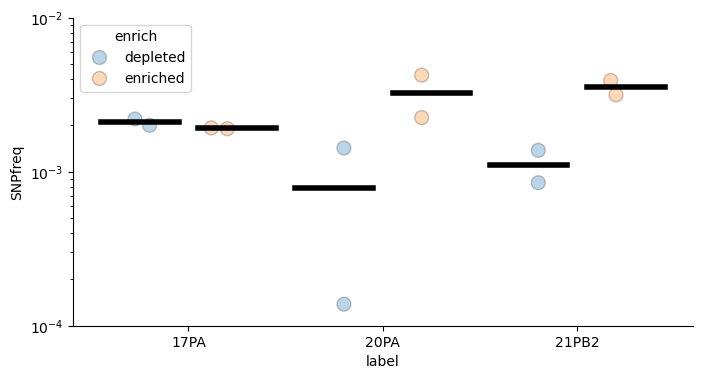

In [10]:
fig, ax = plt.subplots(1,1, figsize=(8,4))
hue_order = ['depleted','enriched']
order = ['17PA', '20PA','21PB2']
sns.swarmplot(y='SNPfreq', x='label', hue='enrich',hue_order=hue_order, data=data,        
                dodge=True, linewidth=1, s=10,   zorder=5, order=order, ax=ax, alpha=0.3)
sns.despine()

plt.ylim(0.0001,0.01)
plt.yscale('log')
for position, strain in enumerate(order):
    bar = 1/len(hue_order)
    for add, mutation in enumerate(hue_order):
        y = data[(data.label == strain) & (data.enrich == mutation)]['SNPfreq'].mean()
        plt.plot([0.5+position-(len(hue_order)-add)*bar+0.05,0.5+position-(len(hue_order)-add)*bar + bar -0.05], [y, y], lw=4, c='k', zorder=9)
if not os.path.isdir(os.path.join('Figures','natSeq')):
    os.mkdir(os.path.join('Figures','natSeq'))
plt.savefig(os.path.join('Figures','natSeq','natSNP.pdf'), format='pdf', bbox_inches = "tight")

In [14]:
#one-tailed t-test from above
pvals = [0.100770114, 0.08670615 ,0.01728432]

multitest.multipletests(pvals, alpha=0.1, method='fdr_bh', is_sorted=False, returnsorted=False)[1]


array([0.10077011, 0.10077011, 0.05185296])

In [13]:
pvals = [0.201540228, 0.1734123, 0.03456864]
multitest.multipletests(pvals, alpha=0.1, method='fdr_bh', is_sorted=False, returnsorted=False)[1]

array([0.20154023, 0.20154023, 0.10370592])